In [2]:
import pandas as pd
import numpy as np
from arch import arch_model
import matplotlib.pyplot as plt


In [3]:
def arch_volatility(df:pd.DataFrame)-> tuple[pd.DataFrame, object]:
    df = df.copy()

    ###### log return
    price = df["Close"].astype(float)
    df["log_return"] = np.log(price/ price.shift(1))*100
    returns = df["log_return"].dropna()

    ########## ARCH model ###############
    model = arch_model(returns, mean="Constant", vol="ARCH", p=1, dist="normal")

    result = model.fit(disp="off")
    df["arch_volatility"] = (result.conditional_volatility)

    return df, result

In [4]:
df = pd.read_csv("C:/Users/Mritunjay Maddhesiya/OneDrive/Desktop/Research_Paper/4_Time_Series/1m_SOL.csv")
data, result = arch_volatility(df)
print(result.summary())

print(data[["Close", "log_return", "arch_volatility"]].tail(20))


                      Constant Mean - ARCH Model Results                      
Dep. Variable:             log_return   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                       ARCH   Log-Likelihood:               -7363.84
Distribution:                  Normal   AIC:                           14733.7
Method:            Maximum Likelihood   BIC:                           14753.5
                                        No. Observations:                 5451
Date:                Sat, Oct 17 2026   Df Residuals:                     5450
Time:                        23:01:00   Df Model:                            1
                                  Mean Model                                 
                 coef    std err          t      P>|t|       95.0% Conf. Int.
-----------------------------------------------------------------------------
mu         2.0351e-03  1.459e-02      0.139      0.889 

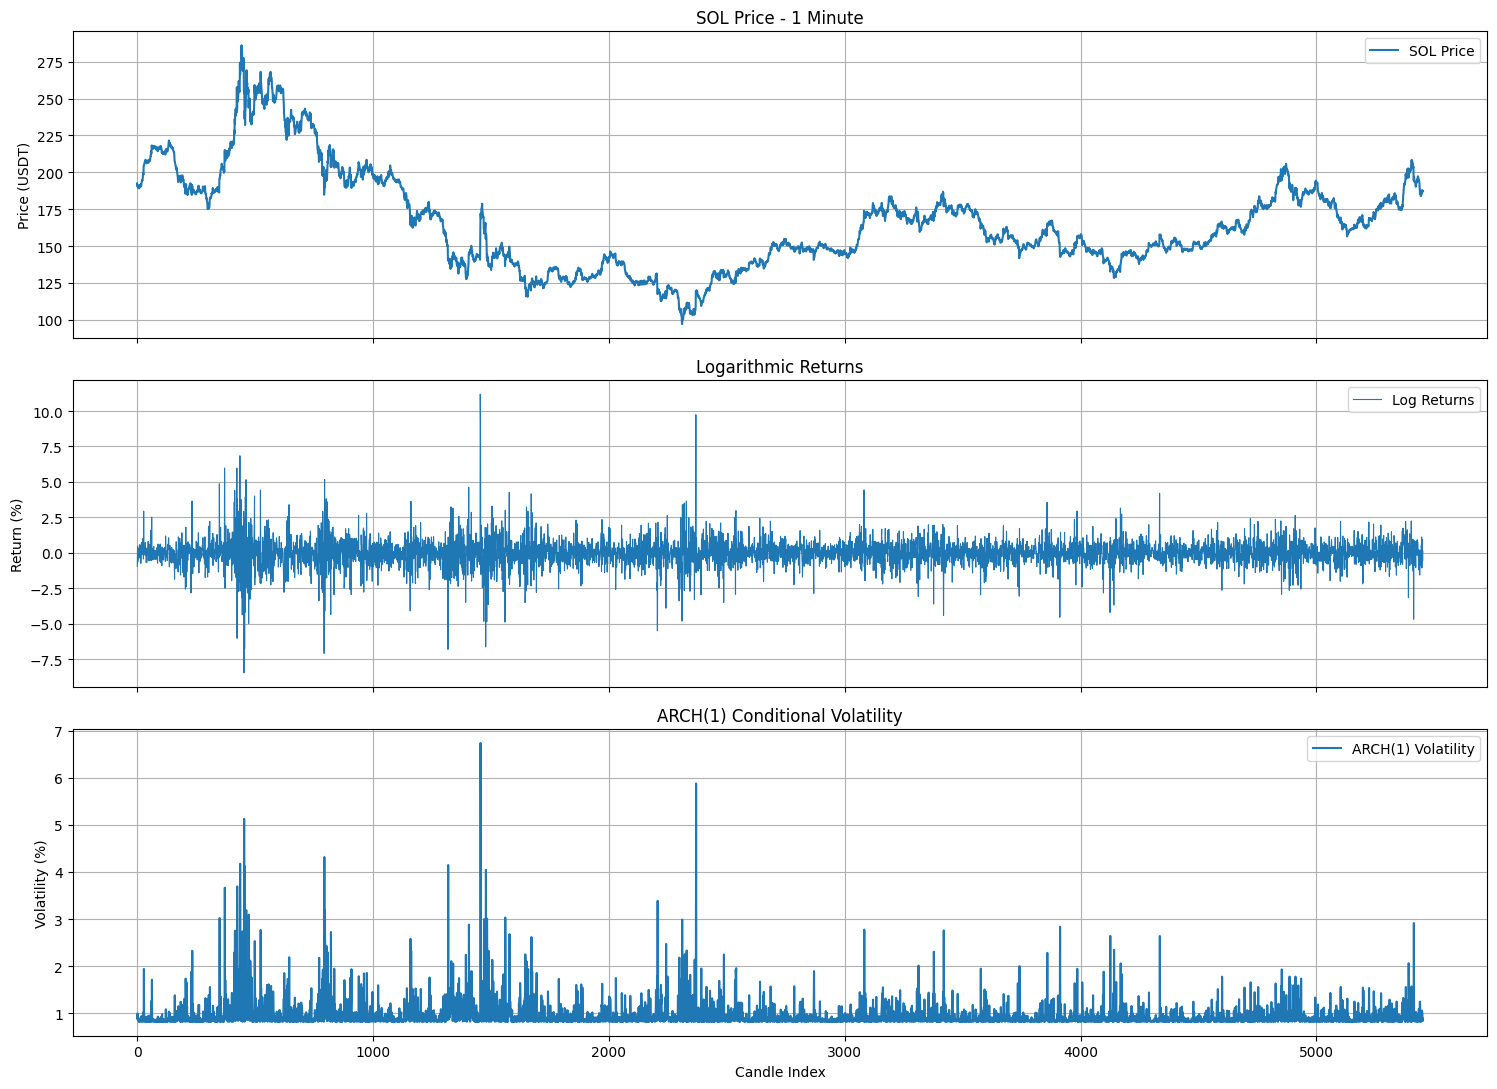

In [6]:
import matplotlib.pyplot as plt

# Plot the last 1000 candles
plot_data = data

fig, axes = plt.subplots(3, 1, figsize=(15, 11), sharex=True)

######## 1. SOL Price
axes[0].plot(plot_data.index,plot_data["Close"],label="SOL Price")
axes[0].set_title("SOL Price - 1 Minute")
axes[0].set_ylabel("Price (USDT)")
axes[0].legend()
axes[0].grid(True)

########## 2. Logarithmic Returns
axes[1].plot(plot_data.index,plot_data["log_return"], label="Log Returns", linewidth=0.8)
axes[1].set_title("Logarithmic Returns")
axes[1].set_ylabel("Return (%)")
axes[1].legend()
axes[1].grid(True)

######## 3. ARCH Volatility
axes[2].plot(plot_data.index,plot_data["arch_volatility"], label="ARCH(1) Volatility")
axes[2].set_title("ARCH(1) Conditional Volatility")
axes[2].set_ylabel("Volatility (%)")
axes[2].set_xlabel("Candle Index")
axes[2].legend()
axes[2].grid(True)

plt.tight_layout()
plt.show()


In [ ]:
###################################################
################# GARCH model #####################

def calculate_garch_volatility(df: pd.DataFrame):
    df    = df.copy()
    price = df["Close"].astype(float)
    df["log_return"] = (np.log(price / price.shift(1)) * 100)
    returns          = df["log_return"].dropna()

    ########### GARCH(1,1) model
    model = arch_model(returns, mean="Constant", vol="GARCH", p=1, q=1, dist="normal")
    result = model.fit(disp="off")

    ########## Fitted conditional volatility (%)
    df["garch_volatility"] = (result.conditional_volatility)

    ############ One-step-ahead forecast
    forecast = result.forecast(horizon=1)

    next_variance = forecast.variance.iloc[-1, 0]
    next_volatility = np.sqrt(next_variance)

    return df, result, next_volatility



data2, result, next_vol = calculate_garch_volatility(df)

print(result.summary())

print("Next 1-minute volatility forecast:", next_vol, "%")


                     Constant Mean - GARCH Model Results                      
Dep. Variable:             log_return   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:               -7024.59
Distribution:                  Normal   AIC:                           14057.2
Method:            Maximum Likelihood   BIC:                           14083.6
                                        No. Observations:                 5451
Date:                Sat, Oct 17 2026   Df Residuals:                     5450
Time:                        23:18:19   Df Model:                            1
                                  Mean Model                                 
                 coef    std err          t      P>|t|       95.0% Conf. Int.
-----------------------------------------------------------------------------
mu         9.1594e-03  1.606e-02      0.570      0.568 

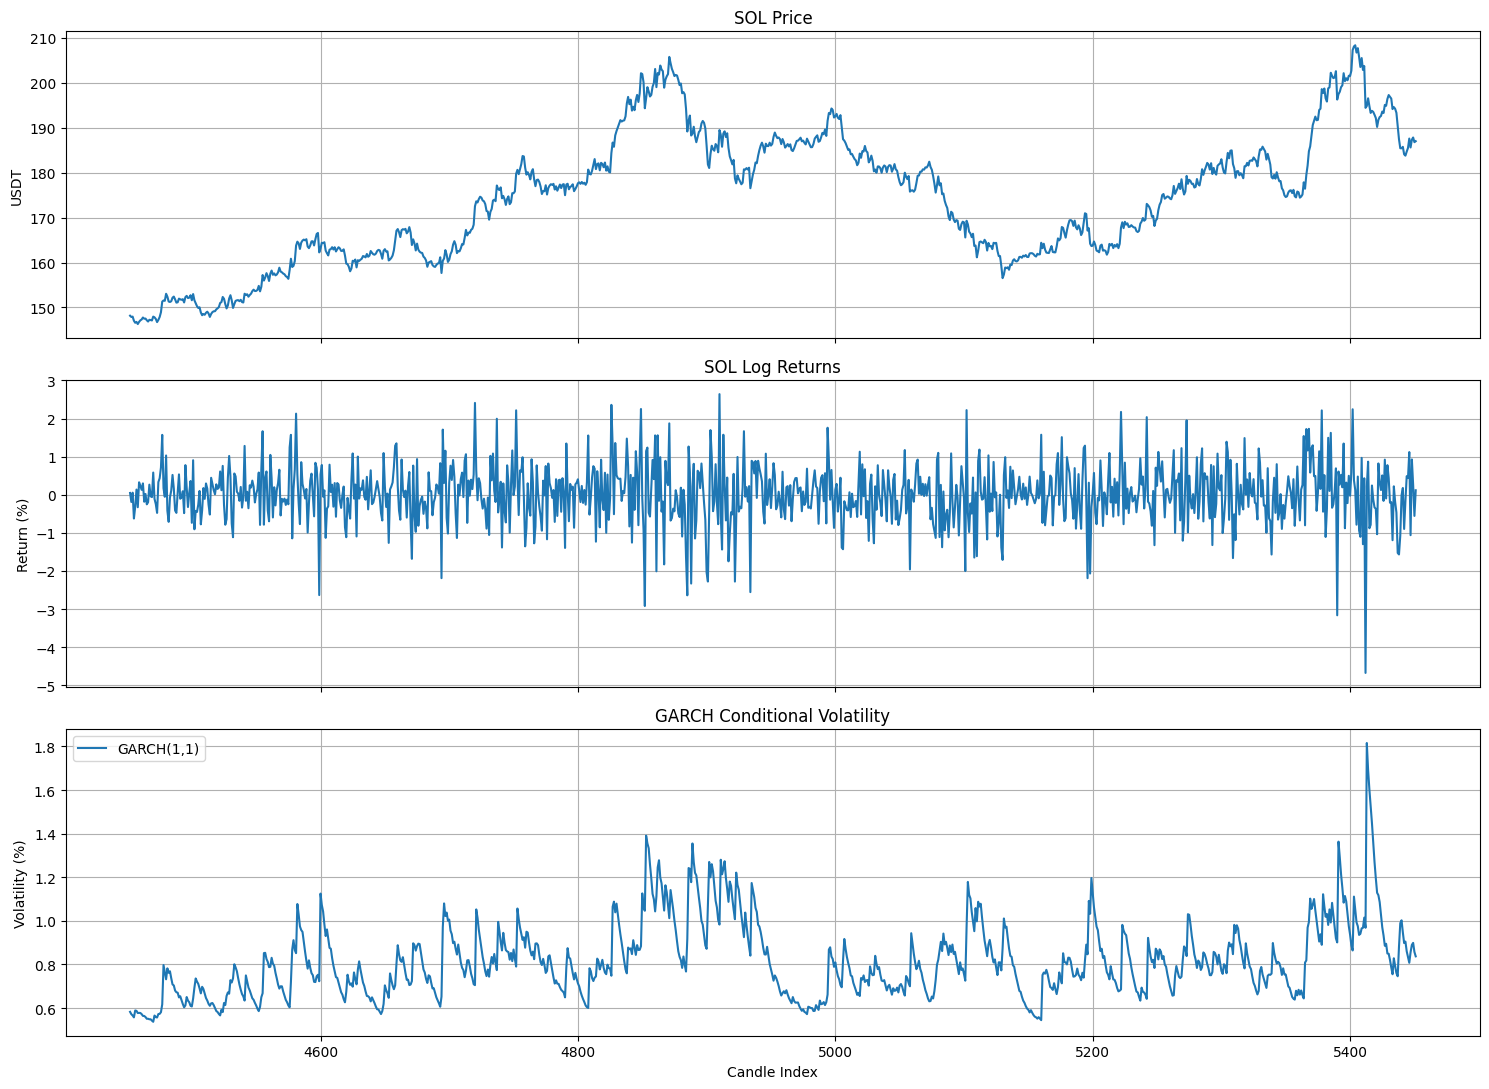

In [9]:


plot_data2 = data2.tail(1000)

fig, axes = plt.subplots(
    3, 1,
    figsize=(15, 11),
    sharex=True
)

axes[0].plot(
    plot_data2.index,
    plot_data2["Close"]
)
axes[0].set_title("SOL Price")
axes[0].set_ylabel("USDT")
axes[0].grid(True)

axes[1].plot(
    plot_data2.index,
    plot_data2["log_return"]
)
axes[1].set_title("SOL Log Returns")
axes[1].set_ylabel("Return (%)")
axes[1].grid(True)

axes[2].plot(
    plot_data2.index,
    plot_data2["garch_volatility"],
    label="GARCH(1,1)"
)
axes[2].set_title("GARCH Conditional Volatility")
axes[2].set_ylabel("Volatility (%)")
axes[2].set_xlabel("Candle Index")
axes[2].legend()
axes[2].grid(True)

plt.tight_layout()
plt.show()


    horizon  forecast_variance  forecast_volatility
0         1           0.637388             0.798366
1         2           0.653102             0.808147
2         3           0.668313             0.817504
3         4           0.683035             0.826459
4         5           0.697286             0.835036
5         6           0.711079             0.843255
6         7           0.724430             0.851135
7         8           0.737353             0.858693
8         9           0.749861             0.865945
9        10           0.761968             0.872908
10       11           0.773687             0.879595
11       12           0.785030             0.886019
12       13           0.796009             0.892193
13       14           0.806636             0.898129
14       15           0.816922             0.903837
15       16           0.826878             0.909328
16       17           0.836515             0.914612
17       18           0.845843             0.919697
18       19 

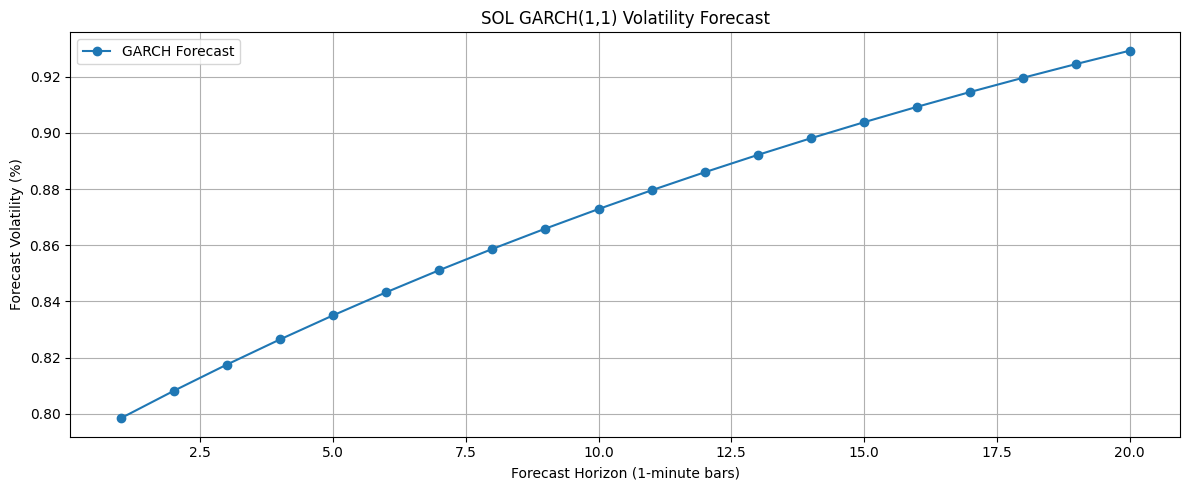

In [11]:
def forecast_garch(result, horizon=20):
    forecast = result.forecast(horizon=horizon, method="analytic", reindex=False)
    variance = forecast.variance.iloc[-1].to_numpy()
    volatility = np.sqrt(variance)
    return pd.DataFrame({
        "horizon": np.arange(1, horizon+1),
        "forecast_variance": variance,
        "forecast_volatility": volatility
    })

forecast_data = forecast_garch(result, horizon=20)

print(forecast_data)
plt.figure(figsize=(12, 5))
plt.plot(forecast_data["horizon"], forecast_data["forecast_volatility"], marker="o", label="GARCH Forecast")
plt.xlabel("Forecast Horizon (1-minute bars)")
plt.ylabel("Forecast Volatility (%)")
plt.title("SOL GARCH(1,1) Volatility Forecast")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()